# One photo at a time: the whole pipeline as it will run in flight

`single_photo_pipeline.py` (next to this notebook) holds the pipeline behind one call, `pipeline.run(photo, prior)`. This notebook does what a flight would do:

1. **Set up once** for the data set we care about: photos and camera, the map at all zoom levels, the feature families, the trained fusion model, the keypoint matcher, the DINO network. This is slow and happens before the first photo.
2. **Evaluation loop:** give the pipeline **one photo at a time**. It never sees the true position. After each answer we compare it with the truth, and we keep the time of every stage.

What you get: the contest score, the share answered, the error, the wrong answers (-20 points), how long each stage takes, which step of the decision answered each photo, and which photos are slow, late or wrong.

Timing is for **this computer**. The target hardware is slower (the Jetson Orin at 15 W took 13 s per photo on average with the submitted code, and a photo that ends after 30 s counts as `no_match`), so use the numbers for comparing stages and spotting slow photos, not as flight timing.

**What the pipeline does with one photo (as of 10 Nov, `tests/Test_Iteration_3/Decision_Report.md`):**

1. Each photo is drawn several times (`HEADINGS` x `SCALE_FACTORS`, 6 queries) and every drawing goes through coarse search, DINO layer and LoFTR. The candidates of all queries are pooled and one is chosen. Measured on 273 development photos: 41.3 -> 49.5 of 60 (see `tests/Heading_Queries/`).
2. **Answer step 1, the bar:** answer when the chosen place has at least `MIN_INLIERS` inliers.
3. **Answer step 2, agreement:** also answer when at least `MIN_AGREE` of the 6 queries each found the same place (within `AGREE_RADIUS_SIGMA` sigma). Two queries rarely make the same chance hit, so this is safe where the bar is not.
4. **Answer step 3, escalation:** a photo still skipped is drawn again with the wide set of 27 queries (`WIDE_HEADINGS` x `WIDE_SCALES`); the 6 queries already run are reused. It is answered only with at least `ESCALATION_MIN_INLIERS` inliers (more queries give false places more chances to collect inliers by luck, so the bar is higher and agreement is not used there).

5. **Inflation guard (`USE_INFLATION_GUARD`, optional):** if a camera or a map gives every candidate more inliers than the development photos did, false places start to reach the bars. The guard measures how many inliers a wrong place gets on this run (a running mean over the photos so far) and raises the bar, the escalation bar and the agreement floor by the same ratio, but only when that ratio is above `GUARD_DEAD_ZONE`. On clean data it changes no answer (four photo sets); with every inlier count multiplied by 1.5 to 2 it brought the wrong answers down from 4 to 11 to 2 to 4 (`tests/Test_Iteration_7/OURS_CHECK.md`). It keeps state between photos, so it only helps when the photos run in one process, as in the loop below.

Set `USE_AGREEMENT = False` to get the older decision (bar only) for comparison. The submitted headless pipeline (`Main_Pipeline_Headless/`) uses a different second pass (12 more queries, same bar, time budget); that is not in this notebook.

# Part 1 · Settings

In [1]:
import os, sys, math, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "single_photo_pipeline.py").exists():
    ROOT = ROOT.parent                    # walk up to the repo folder
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

# ------------------------------------------------------------------ settings: change here, run again
DATA = "official"           # "official" (d1 photos; map from src/header/map_source.py: the new two-scene base map) or "nudt" (Changsha test photos)
MAP = "new"                # base map of the official photos: "new" (both scenes), "new_931", "new_921" (one scene each) or "old" (small_sat_area). Ignored for DATA = "nudt"
MAP_MARGIN_M = None         # metres of new map kept around the photos (None = 6000 from src/header/map_source.py; 2500 builds a much smaller, faster map)
N_PHOTOS = 500              # photos loaded for the data set (spread over the flights)
N_EVAL = 100                # photos sent through the loop, one at a time
COARSE = "edge_zncc"        # "fused" (learned fusion of six maps) or "edge_zncc" (edges only). The heading queries were measured with edge_zncc
USE_SEMANTIC_LAYER = True   # DINO re-orders the K coarse places before the fine stage
K_PEAKS = 50                # K: places the coarse search returns (the shortlist the DINO layer looks at); with heading queries: per query
M_FINE = 10                 # M <= K: places sent to the fine stage (per query when heading queries are on; 10 was measured) (with the DINO layer: the top M after DINO; without it: the first M of the coarse order)
MATCHER = "loftr_minima"    # fine matcher: "lightglue" (SuperPoint + LightGlue), "loftr_minima" (LoFTR, MINIMA weights) or "roma_minima" (RoMa). LoFTR/RoMa inlier counts are in the hundreds/thousands, not tens: the 12-inlier bar and GAMMA/RESCUE below need retuning
MIN_INLIERS = 8             # answer bar: answer when the chosen place has at least this many inliers (None = 12 from settings; for LoFTR try 5 to 8)
RANSAC_PIXELS = None        # a match is an inlier when it is within this many pixels of the fitted transform (None = 3.0 from settings)
MATCHER_CONFIDENCE = 0.21   # LoFTR only: matches with a lower confidence are dropped before RANSAC (0.2 = kornia's default; 0.1 scored higher on the development photos but lets weak, possibly false matches through)
LOFTR_COARSE_THRESHOLD = 0.21  # LoFTR only: its own cut on the coarse match probability (None = 0.2)
LOFTR_BORDER_PX = 0            # LoFTR only: matches within this many pixels of the edge of the really photographed canvas area are dropped (0 = keep all)
LOFTR_MARGIN = 0               # LoFTR only: grey / map pixels added around the canvas and the map window before matching (a multiple of 4: 0, 8, 16 ...)
USE_SEMANTIC_DECISION = True    # the DINO score also takes part in choosing the answer
GAMMA = 1.0                     # choose by  inliers + GAMMA * (DINO z-score);  0 = inliers only
RESCUE_INLIERS = None           # e.g. 9: also answer with this many inliers (instead of 12) ...
RESCUE_Z = None                 # ... when the DINO z-score of the chosen place is at least this (e.g. 2.0)
DINO_WEIGHT = None              # DINO's weight when it re-orders the K shortlist: 0 = keep the coarse order, 100 = DINO decides (None = 100 from semantic_rerank/dino_rerank.py)
SCALE = None                    # photo-to-map projection: multiplies the flight height (None = 1.04 from settings.GEOMETRY); 0.9 to 1.1 is a sensible range
YAW_OFFSET = None               # degrees added to the photo's yaw (None = 180.0 from settings.GEOMETRY)
HEIGHT_OFFSET = None            # metres added to the flight height before SCALE (None = 0.0 from settings.GEOMETRY)
USE_HEADING_QUERIES = True      # draw the photo once for each (heading, scale) pair and choose the answer among all the candidates
HEADINGS = [-5.0, 0.0, 5.0]     # degrees added to the photo's yaw, one query each (must contain 0.0). Metadata yaw is a few degrees off for some photos
SCALE_FACTORS = [1.0, 1.05]     # the projection scale is multiplied by each of these (must contain 1.0). Queries per photo = headings x scales = 6

# the decision after the queries (needs USE_HEADING_QUERIES)
USE_AGREEMENT = True            # True: answer at the bar or when queries agree, then escalate skipped photos (AgreementQueryPipeline); False: answer at the bar only (HeadingQueryPipeline)
MIN_AGREE = 2                   # queries that must find the same place (a query always agrees with itself, so at least 2)
AGREE_RADIUS_SIGMA = 1.0        # two queries found the same place when their answers are this close (in sigma)
AGREE_QUERY_INLIERS = 3         # a query only counts in the agreement when its own best candidate has at least this many inliers
ESCALATE = True                 # a photo skipped by the first step is run again with the wide queries below
WIDE_HEADINGS = [-10.0, -7.5, -5.0, -2.5, 0.0, 2.5, 5.0, 7.5, 10.0]   # escalation: 9 headings ...
WIDE_SCALES = [0.95, 1.0, 1.05]                                         # ... x 3 scales = 27 queries
ESCALATION_MIN_INLIERS = 11     # escalation answers only at this many inliers (false places reached 10 on the development photos, never 11)
# wider scale coverage for the escalation (not the default, measured on one set): WIDE_HEADINGS = [-5.0, 0.0, 5.0] and WIDE_SCALES = [0.80, 0.85, 0.90, 1.0, 1.05] (15 queries) keep the clean
# answers and take the score on 60 official photos with the height metadata 20 % too high from 18.8 to 43.6 /60 (6 standard queries: 18.8). Not yet checked on NUDT.
USE_INFLATION_GUARD = True      # needs USE_AGREEMENT: the bars rise when wrong places collect more inliers than on the development photos; no change on clean data
GUARD_PRIOR = 0.169             # mean inliers of a wrong place (more than 4 sigma from the answer) on the development photos, from the 6 standard queries
GUARD_PRIOR_WEIGHT = 30         # the prior counts like this many photos
GUARD_DEAD_ZONE = 1.5           # the bars change only when the running level is more than this many times the prior

LOFTR_BATCH = 5             # LoFTR pairs per network call (1 = one at a time). Measured: 5 is 1.13x faster for 0.95 GB, 10 is 1.17x for 1.7 GB, 30 ran out of memory (Batch_Speed_Check.ipynb); the answers are identical
DINO_BATCH = 25             # DINO map windows per call
QUERY_GROUP = 1             # heading queries whose LoFTR pairs are matched together (1 = each alone; only with USE_HEADING_QUERIES)

# time: the evaluation answers one photo in 30 s at most, later answers count as no_match
TIME_BUDGET_S = 22          # the submitted code stops starting new queries after this (here it only flags the photo)
TIME_LIMIT_S = 30           # a photo that takes longer than this scores 0 in the 'time limit' score below
SEED = 958476
plt.rcParams["figure.dpi"] = 90

# Part 2 · Set up once

`SinglePhotoPipeline(...)` only stores the choices. `setup()` does the slow work for the data set. Nothing here depends on a single photo, so in flight it would run before the first photo arrives.

In [2]:
from single_photo_pipeline import SinglePhotoPipeline, STAGES      # first import: it saves the development-set settings before NUDT changes them
from heading_query_pipeline import HeadingQueryPipeline
from agreement_query_pipeline import AgreementQueryPipeline
from inflation_guard_pipeline import InflationGuardPipeline
from src.header.scoring import points_for_error, final_score

pipeline_settings = dict(loftr_batch=LOFTR_BATCH, dino_batch=DINO_BATCH, semantic_layer=USE_SEMANTIC_LAYER, semantic_decision=USE_SEMANTIC_DECISION,
                               gamma=GAMMA, rescue_inliers=RESCUE_INLIERS, rescue_z=RESCUE_Z,
                               k_peaks=K_PEAKS, m_fine=M_FINE, matcher=MATCHER,
                               min_inliers=MIN_INLIERS, ransac_pixels=RANSAC_PIXELS, matcher_confidence=MATCHER_CONFIDENCE, satellite=MAP, map_margin_m=MAP_MARGIN_M, loftr_coarse_threshold=LOFTR_COARSE_THRESHOLD,
                               loftr_border_px=LOFTR_BORDER_PX, loftr_margin=LOFTR_MARGIN,
                               dino_weight=DINO_WEIGHT, geometry={k: v for k, v in dict(scale=SCALE, yaw_offset=YAW_OFFSET, height_offset=HEIGHT_OFFSET).items() if v is not None})
if USE_HEADING_QUERIES and USE_AGREEMENT:
    agreement_settings = dict(headings=HEADINGS, scale_factors=SCALE_FACTORS, wide_headings=WIDE_HEADINGS, wide_scales=WIDE_SCALES,
                              min_agree=MIN_AGREE, agree_radius_sigma=AGREE_RADIUS_SIGMA, agree_query_inliers=AGREE_QUERY_INLIERS,
                              escalation_min_inliers=ESCALATION_MIN_INLIERS, escalate=ESCALATE, query_group=QUERY_GROUP)
    if USE_INFLATION_GUARD:
        pipeline = InflationGuardPipeline(DATA, COARSE, prior=GUARD_PRIOR, prior_weight=GUARD_PRIOR_WEIGHT, dead_zone=GUARD_DEAD_ZONE,
                                          **agreement_settings, **pipeline_settings)
    else:
        pipeline = AgreementQueryPipeline(DATA, COARSE, **agreement_settings, **pipeline_settings)
elif USE_HEADING_QUERIES:
    pipeline = HeadingQueryPipeline(DATA, COARSE, headings=HEADINGS, scale_factors=SCALE_FACTORS, query_group=QUERY_GROUP, **pipeline_settings)
else:
    pipeline = SinglePhotoPipeline(DATA, COARSE, **pipeline_settings)
start = time.time()
pipeline.setup(N_PHOTOS, SEED)
print("setup done in %.1f s" % (time.time() - start))
for line in pipeline.describe():
    print(line)

setup_table = pd.DataFrame({"seconds": pipeline.setup_seconds})
display(setup_table.round(2))

test_set = pipeline.test_set
camera = pipeline.camera
heights = np.array([item["rel_height"] for item in test_set.items])
print("%d photos, flight height %.0f to %.0f m" % (len(heights), heights.min(), heights.max()))

level 3: 0.85 m/pixel, picture 16378 x 16004, map coverage 100%
level 4: 1.20 m/pixel, picture 11581 x 11316, map coverage 100%
level 5: 1.70 m/pixel, picture 8189 x 8002, map coverage 100%
level 6: 2.40 m/pixel, picture 5790 x 5658, map coverage 100%
level 7: 3.39 m/pixel, picture 4094 x 4001, map coverage 100%


map store ready, took 116 s


/home/voidness/Storage/Synced Folders/InterIIT Tech 15/venv-geoloc/lib/python3.10/site-packages/kornia/feature/lightglue.py:44: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @torch.cuda.amp.custom_fwd(cast_inputs=torch.float32)


/home/voidness/Storage/Synced Folders/InterIIT Tech 15/venv-geoloc/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


setup done in 132.4 s
data: official | 379 photos available | zoom levels [3, 4, 5, 6, 7]
photos: official | map: new
coarse method: edge_zncc | maps: ['edge_zncc']
semantic layer: on (best K=50 -> M=10) | DINO in the decision: on (gamma 1.00, rescue (None, None))
fine matcher: loftr_minima | answer bar: 8 inliers | RANSAC 3.0 px | matcher confidence 0.21 | LoFTR coarse threshold 0.21, upscale 1.0 | border 0 px, margin 0 px
DINO order weight: 100.0 | projection overrides: none (settings.GEOMETRY)
batches: 5 LoFTR pairs and 25 DINO places per call
device: cuda
queries per photo: 6 (headings [-5.0, 0.0, 5.0], scale factors [1.0, 1.05]); K and M are per query; 1 queries matched together
decision: answer at >= 8 inliers or >= 2 queries agreeing within 1.0 sigma (each >= 3 inliers)
escalation: on; 27 wide queries, answer at >= 11 inliers
inflation guard: prior 0.169 (weight 30 photos), dead zone x1.5; bars scale with the running far-candidate level


,seconds
DINO encoder,1.42
"feature families (edge, MIND, learned)",0.00
fine matcher (LoFTR + MINIMA weights),0.20
map at all zoom levels + edge features,116.44
"photos, camera and map",14.30


379 photos, flight height 100 to 351 m


# Part 3 · Warm-up

The first call is slower than the later ones (GPU kernels are compiled, caches are filled). In flight this would be done on the ground, so one photo is run and its time is kept apart from the loop.

In [3]:
warm = pipeline.run(test_set.items[0], test_set.priors[0])
print("warm-up photo: %.1f s in total" % warm["total"])
print({label: round(warm["seconds"][label], 2) for label in STAGES})

warm-up photo: 6.0 s in total
{'render': 0.04, 'maps': 2.69, 'coarse': 0.01, 'semantic': 1.03, 'fine': 2.17, 'decision': 0.0}


# Part 4 · The evaluation loop: one photo in, one answer out

For each photo: `pipeline.run(photo, prior)`. The pipeline gets the photo record and the rough 5 km hint, **not** the truth. The truth is used here only to judge the answer: error in metres and in sigma, and the contest points (a skipped photo gets 0, a wrong answer −20).

In [4]:
rows = []
failures = []
loop_start = time.time()
count = min(N_EVAL, len(test_set.items))
for index in range(count):
    item = test_set.items[index]
    try:
        result = pipeline.run(item, test_set.priors[index])
    except Exception as error:
        failures.append(dict(photo=index, error="%s: %s" % (type(error).__name__, str(error)[:120])))
        print("photo %d failed: %s: %s" % (index, type(error).__name__, str(error)[:120]))
        continue

    truth_x, truth_y = test_set.truths[index]
    error_m = math.hypot(result["x"] - truth_x, result["y"] - truth_y)
    earned = points_for_error(error_m, item["rel_height"], camera.fx)
    if result["answered"]:
        points = earned
    else:
        points = 0

    answer_lat, answer_lon = pipeline.satellite_map.metres_to_gps(result["x"], result["y"])      # the answer (metres on the map) as latitude, longitude
    row = dict(photo=index, true_lat=item["lat"], true_lon=item["lon"], lat=answer_lat, lon=answer_lon,
               height=item["rel_height"], level=result["level"], sigma_m=test_set.sigmas[index],
               error_m=error_m, error_sigma=error_m / test_set.sigmas[index], answered=result["answered"],
               inliers=result["inliers"], chosen=result["chosen"], z_chosen=result["z_chosen"], points=points)
    if USE_AGREEMENT and USE_HEADING_QUERIES:
        row["stage"] = result["stage"]
        row["agreement"] = result["agreement"]
        row["escalated"] = result["escalated"]
        row["n_queries"] = result["n_queries_run"]
        if USE_INFLATION_GUARD:
            row["guard_factor"] = result["guard_factor"]
            row["far_level"] = result["far_level"]
    else:
        if result["answered"]:
            row["stage"] = "bar"
        else:
            row["stage"] = "skip"
        row["agreement"] = 0
        row["escalated"] = False
        if USE_HEADING_QUERIES:
            row["n_queries"] = len(pipeline.queries)
        else:
            row["n_queries"] = 1
    if USE_HEADING_QUERIES:
        chosen_query = result["queries"][result["owner"][result["chosen"]]]
        row["chosen_heading"] = chosen_query["heading"]
        row["chosen_scale"] = chosen_query["scale_factor"]
    for label in STAGES:
        row["t_" + label] = result["seconds"][label]
    row["t_total"] = result["total"]
    row["late"] = result["total"] > TIME_LIMIT_S
    if row["late"]:
        row["points_in_time"] = 0
    else:
        row["points_in_time"] = points
    row["gpu_peak_mb"] = result["gpu_peak_mb"]
    rows.append(row)

    if (index + 1) % 10 == 0:
        so_far = pd.DataFrame(rows)
        print("photo %3d/%d | score so far %.1f /60 | answered %.2f | mean %.1f s per photo | slowest %.1f s" % (
            index + 1, count, final_score(list(so_far["points"])), so_far["answered"].mean(), so_far["t_total"].mean(), so_far["t_total"].max()))

results = pd.DataFrame(rows)
print("%d photos done in %.0f s (%d failed)" % (len(results), time.time() - loop_start, len(failures)))

photo  10/100 | score so far 54.0 /60 | answered 0.90 | mean 6.4 s per photo | slowest 26.2 s


photo  20/100 | score so far 53.4 /60 | answered 0.95 | mean 5.0 s per photo | slowest 26.2 s


photo  30/100 | score so far 55.6 /60 | answered 0.97 | mean 4.6 s per photo | slowest 26.2 s


photo  40/100 | score so far 53.7 /60 | answered 0.93 | mean 5.7 s per photo | slowest 26.8 s


photo  50/100 | score so far 53.8 /60 | answered 0.92 | mean 5.7 s per photo | slowest 26.8 s


photo  60/100 | score so far 52.8 /60 | answered 0.90 | mean 5.8 s per photo | slowest 26.8 s


photo  70/100 | score so far 51.4 /60 | answered 0.89 | mean 6.0 s per photo | slowest 26.8 s


photo  80/100 | score so far 52.2 /60 | answered 0.90 | mean 5.7 s per photo | slowest 26.8 s


photo  90/100 | score so far 53.1 /60 | answered 0.91 | mean 5.7 s per photo | slowest 26.8 s


photo 100/100 | score so far 52.6 /60 | answered 0.90 | mean 5.7 s per photo | slowest 26.8 s
100 photos done in 569 s (0 failed)


## 4.1 True position against the answer

One row per photo: the true latitude and longitude (from the photo's metadata, never seen by the pipeline), the latitude and longitude the pipeline returned, the distance between them, and whether it answered (a skipped photo still shows its best guess, but scores 0).

In [5]:
positions = results[["photo", "true_lat", "true_lon", "lat", "lon", "error_m", "answered"]]

# as an array: one row per photo = [true_lat, true_lon, returned_lat, returned_lon]
true_vs_returned = results[["true_lat", "true_lon", "lat", "lon"]].to_numpy()
np.set_printoptions(precision=6, suppress=True, linewidth=120)
print("true_vs_returned:", true_vs_returned.shape, "(photos, [true_lat, true_lon, returned_lat, returned_lon])")
print(true_vs_returned[:10])
display(positions.head(10).round(6))


true_vs_returned: (100, 4) (photos, [true_lat, true_lon, returned_lat, returned_lon])
[[19.124083 73.084061 19.1241   73.084077]
 [19.131329 73.083893 19.131352 73.083856]
 [19.127205 73.081482 19.127156 73.081524]
 [19.128729 73.080231 19.128767 73.080212]
 [19.122801 73.077271 19.122858 73.077308]
 [19.12833  73.087555 19.128366 73.087554]
 [19.127827 73.087448 19.127829 73.087474]
 [19.12674  73.077515 19.126756 73.077561]
 [19.133162 73.081566 19.13317  73.081569]
 [19.127726 73.091942 19.090464 73.058219]]


,photo,true_lat,true_lon,lat,lon,error_m,answered
0,0,19.124083,73.084061,19.124100,73.084077,2.506451,True
1,1,19.131329,73.083893,19.131352,73.083856,4.629476,True
2,2,19.127205,73.081482,19.127156,73.081524,6.953617,True
3,3,19.128729,73.080231,19.128767,73.080212,4.640941,True
4,4,19.122801,73.077271,19.122858,73.077308,7.450448,True
5,5,19.128330,73.087555,19.128366,73.087554,3.972941,True
6,6,19.127827,73.087448,19.127829,73.087474,2.724179,True
7,7,19.126740,73.077515,19.126756,73.077561,5.169316,True
8,8,19.133162,73.081566,19.133170,73.081569,0.972625,True
9,9,19.127726,73.091942,19.090464,73.058219,5441.524211,False


# Part 5 · What came out

## 5.1 Score and accuracy

In [6]:
summary = pd.DataFrame([{
    "photos": len(results),
    "score (/60)": final_score(list(results["points"])),
    "answered": results["answered"].mean(),
    "answer <= 1 sigma": (results["error_sigma"] <= 1).mean(),
    "answer <= 2 sigma": (results["error_sigma"] <= 2).mean(),
    "answer <= 4 sigma": (results["error_sigma"] <= 4).mean(),
    "median error (m)": results["error_m"].median(),
    "wrong answers": int((results["points"] < 0).sum()),
    "late (> %d s)" % TIME_LIMIT_S: int(results["late"].sum()),
    "score if late = no_match": final_score(list(results["points_in_time"])),
}])
display(summary.round(3))

earned_table = []
labels = [(10, "within 1 sigma (+10)"), (6, "within 2 sigma (+6)"), (3, "within 4 sigma (+3)"), (0, "answered, 4 to 8 sigma (0)"), (-20, "answered, wrong place (-20)")]
for value, label in labels:
    earned_table.append({"what the photo earned": label, "photos": int(((results["answered"]) & (results["points"] == value)).sum())})
earned_table.append({"what the photo earned": "skipped (0)", "photos": int((~results["answered"]).sum())})
display(pd.DataFrame(earned_table))
print("Of the skipped photos, %d had an answer within 4 sigma that was held back (fewer than the needed inliers)." % int(((~results["answered"]) & (results["error_sigma"] <= 4)).sum()))

,photos,score (/60),answered,answer <= 1 sigma,answer <= 2 sigma,answer <= 4 sigma,median error (m),wrong answers,late (> 30 s),score if late = no_match
0,100,52.56,0.9,0.87,0.93,0.93,5.105,0,0,52.56


,what the photo earned,photos
0,within 1 sigma (+10),84
1,within 2 sigma (+6),6
2,within 4 sigma (+3),0
3,"answered, 4 to 8 sigma (0)",0
4,"answered, wrong place (-20)",0
5,skipped (0),10


Of the skipped photos, 3 had an answer within 4 sigma that was held back (fewer than the needed inliers).


## 5.1b Which step of the decision answered each photo

`bar` = the chosen place had enough inliers; `agreement` = too few inliers, but several queries found the same place; `escalation` = answered after the 27 wide queries; `skip` = no answer. The second table builds the score up step by step from the same run (a photo answered by a later step counts 0 in the earlier rows), so you see what agreement and escalation add and what they cost in wrong answers and time. Without `USE_AGREEMENT` every answer is a `bar` answer. With `USE_INFLATION_GUARD` a last table shows the guard: `far_level` is the mean inliers of the wrong places of each photo and `guard_factor` is 1.0 while the running level stays inside the dead zone (it should on the development photos).

In [7]:
step_rows = []
for step in ["bar", "agreement", "escalation", "skip"]:
    part = results[results["stage"] == step]
    row = {"decision step": step, "photos": len(part), "wrong answers": int((part["points"] < 0).sum()), "points": int(part["points"].sum())}
    if len(part) > 0:
        row["mean queries"] = part["n_queries"].mean()
        row["mean seconds"] = part["t_total"].mean()
    else:
        row["mean queries"] = np.nan
        row["mean seconds"] = np.nan
    step_rows.append(row)
display(pd.DataFrame(step_rows).round(2))

# the score with only the first steps answering: later steps count as skipped
step_names = [("bar only", ["bar"]), ("+ agreement", ["bar", "agreement"]), ("+ escalation", ["bar", "agreement", "escalation"])]
build_rows = []
for label, allowed in step_names:
    points_list = []
    wrong = 0
    answered_count = 0
    for position in range(len(results)):
        if results["stage"].iloc[position] in allowed:
            points_list.append(int(results["points"].iloc[position]))
            answered_count += 1
        else:
            points_list.append(0)
    for value in points_list:
        if value < 0:
            wrong += 1
    build_rows.append({"answers allowed from": label, "score (/60)": final_score(points_list), "wrong answers": wrong, "answered": answered_count})
display(pd.DataFrame(build_rows).round(2))

# the same score by flight height: agreement and escalation help the photos the bar misses, which are not spread evenly
height_rows = []
for low, high in [(0, 150), (150, 250), (250, 1000)]:
    part = results[(results["height"] >= low) & (results["height"] < high)]
    if len(part) > 0:
        height_rows.append({"flight height (m)": "%d to %d" % (low, high), "photos": len(part), "score (/60)": final_score(list(part["points"])),
                            "skipped": int((~part["answered"]).sum()), "wrong answers": int((part["points"] < 0).sum()), "mean seconds": part["t_total"].mean()})
display(pd.DataFrame(height_rows).round(2))

# the inflation guard: how many inliers the wrong places get on this run, and whether the bars were ever raised
if USE_AGREEMENT and USE_HEADING_QUERIES and USE_INFLATION_GUARD:
    guard_table = pd.DataFrame([{"mean far_level": results["far_level"].mean(), "prior": GUARD_PRIOR, "photos with guard_factor above 1": int((results["guard_factor"] > 1.0).sum()),
                                 "largest guard_factor": results["guard_factor"].max()}])
    display(guard_table.round(3))

,decision step,photos,wrong answers,points,mean queries,mean seconds
0,bar,83,0,806,6.0,3.73
1,agreement,5,0,50,6.0,4.69
2,escalation,2,0,20,27.0,14.90
3,skip,10,0,0,27.0,20.63


,answers allowed from,score (/60),wrong answers,answered
0,bar only,48.36,0,83
1,+ agreement,51.36,0,88
2,+ escalation,52.56,0,90


,flight height (m),photos,score (/60),skipped,wrong answers,mean seconds
0,0 to 150,45,48.80,8,0,7.94
1,150 to 250,14,58.29,0,0,4.47
2,250 to 1000,41,54.73,2,0,3.64


,mean far_level,prior,photos with guard_factor above 1,largest guard_factor
0,0.049,0.169,0,1.0


## 5.2 Time: where it goes

,mean (s),median (s),95th percentile (s),max (s)
render,0.05,0.04,0.16,0.19
maps,1.86,1.15,11.69,13.47
coarse,0.01,0.01,0.05,0.05
semantic,0.87,0.62,2.83,3.24
fine,2.85,2.04,8.64,9.79
decision,0.00,0.00,0.00,0.00
total,5.69,3.78,23.43,26.81


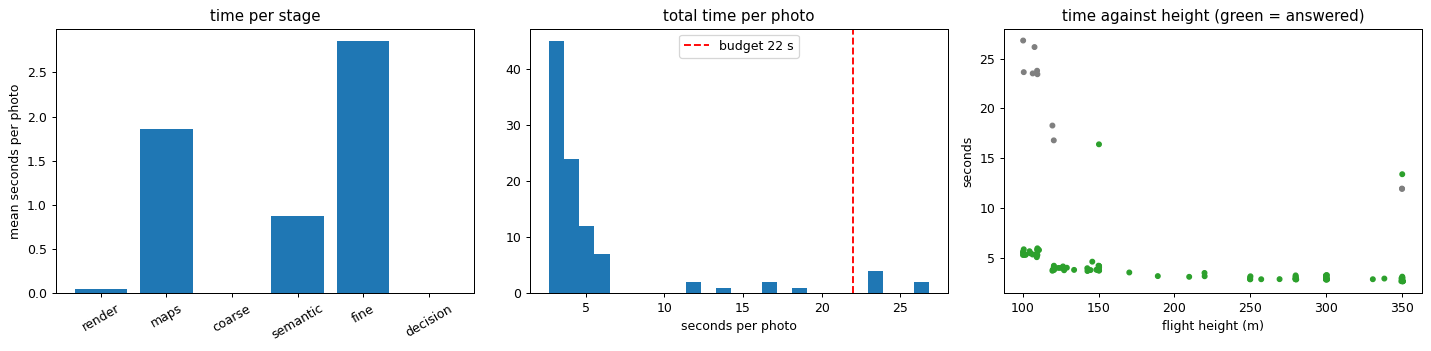

6 photos over the 22 s budget on this computer. GPU memory peak: 2921 MB


In [8]:
stage_columns = ["t_" + label for label in STAGES]
timing = results[stage_columns + ["t_total"]].describe(percentiles=[0.5, 0.95]).T[["mean", "50%", "95%", "max"]]
timing.index = [name[2:] for name in timing.index]
timing.columns = ["mean (s)", "median (s)", "95th percentile (s)", "max (s)"]
display(timing.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(STAGES, [results["t_" + label].mean() for label in STAGES])
axes[0].set_ylabel("mean seconds per photo")
axes[0].set_title("time per stage")
axes[0].tick_params(axis="x", rotation=30)
axes[1].hist(results["t_total"], bins=25)
axes[1].axvline(TIME_BUDGET_S, color="red", ls="--", label="budget %d s" % TIME_BUDGET_S)
axes[1].set_xlabel("seconds per photo")
axes[1].set_title("total time per photo")
axes[1].legend()
colours = ["tab:green" if answered else "tab:gray" for answered in results["answered"]]
axes[2].scatter(results["height"], results["t_total"], c=colours, s=14)
axes[2].set_xlabel("flight height (m)")
axes[2].set_ylabel("seconds")
axes[2].set_title("time against height (green = answered)")
plt.tight_layout()
plt.show()

over = (results["t_total"] > TIME_BUDGET_S).sum()
print("%d photos over the %d s budget on this computer. GPU memory peak: %.0f MB" % (over, TIME_BUDGET_S, results["gpu_peak_mb"].max()))

In [9]:
# time by decision step, and the photos the 30 s limit would turn into no_match
time_rows = []
for step in ["bar", "agreement", "escalation", "skip"]:
    part = results[results["stage"] == step]
    if len(part) > 0:
        time_rows.append({"decision step": step, "photos": len(part), "mean (s)": part["t_total"].mean(), "max (s)": part["t_total"].max(),
                          "mean queries run": part["n_queries"].mean(), "seconds per query": part["t_total"].sum() / part["n_queries"].sum()})
display(pd.DataFrame(time_rows).round(2))

escalated_photos = results[results["escalated"]]
other_photos = results[~results["escalated"]]
print("not escalated: %d photos, %.1f s on average" % (len(other_photos), other_photos["t_total"].mean()))
if len(escalated_photos) > 0:
    print("escalated:     %d photos, %.1f s on average (the 27 wide queries cost about 4.5 times the 6 standard ones)" % (len(escalated_photos), escalated_photos["t_total"].mean()))

late_count = int(results["late"].sum())
over_budget = int((results["t_total"] > TIME_BUDGET_S).sum())
print("%d photos over the %d s budget, %d over the %d s limit (these would be no_match)" % (over_budget, TIME_BUDGET_S, late_count, TIME_LIMIT_S))
print("score as measured %.2f, score with late photos as no_match %.2f" % (final_score(list(results["points"])), final_score(list(results["points_in_time"]))))

,decision step,photos,mean (s),max (s),mean queries run,seconds per query
0,bar,83,3.73,5.97,6.0,0.62
1,agreement,5,4.69,5.53,6.0,0.78
2,escalation,2,14.90,16.40,27.0,0.55
3,skip,10,20.63,26.81,27.0,0.76


not escalated: 88 photos, 3.8 s on average
escalated:     12 photos, 19.7 s on average (the 27 wide queries cost about 4.5 times the 6 standard ones)
6 photos over the 22 s budget, 0 over the 30 s limit (these would be no_match)
score as measured 52.56, score with late photos as no_match 52.56


## 5.3 Errors and the photos to look at

The slowest photos and the wrong answers. Open one in `Pipeline_Visual_Check.ipynb` (set `PHOTO`) to see why.

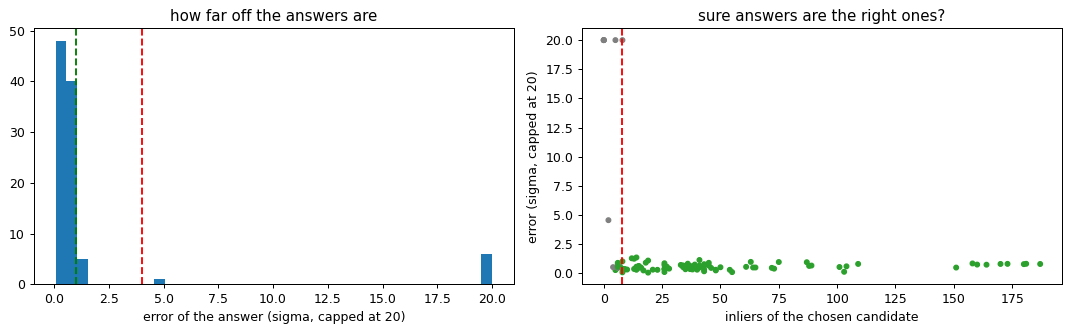

slowest photos


,photo,height,level,error_sigma,answered,inliers,points,t_total
38,38,100.2,3,0.48,False,6,0,26.81
9,9,107.7,3,666.77,False,0,0,26.15
65,65,109.4,3,403.38,False,5,0,23.78
61,61,100.6,3,361.90,False,8,0,23.64
43,43,106.5,3,621.75,False,0,0,23.51


wrong answers that cost 20 points


,photo,height,level,error_sigma,answered,inliers,points,t_total


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(results["error_sigma"].clip(upper=20), bins=40)
axes[0].axvline(1, color="green", ls="--")
axes[0].axvline(4, color="red", ls="--")
axes[0].set_xlabel("error of the answer (sigma, capped at 20)")
axes[0].set_title("how far off the answers are")
axes[1].scatter(results["inliers"], results["error_sigma"].clip(upper=20), c=colours, s=14)
axes[1].axvline(pipeline.min_inliers, color="red", ls="--")
axes[1].set_xlabel("inliers of the chosen candidate")
axes[1].set_ylabel("error (sigma, capped at 20)")
axes[1].set_title("sure answers are the right ones?")
plt.tight_layout()
plt.show()

columns = ["photo", "height", "level", "error_sigma", "answered", "inliers", "points", "t_total"]
print("slowest photos")
display(results.sort_values("t_total", ascending=False)[columns].head(5).round(2))
print("wrong answers that cost 20 points")
display(results[results["points"] < 0][columns].round(2))
if len(failures) > 0:
    print("photos that raised an error")
    display(pd.DataFrame(failures))

## 5.4 Save the per-photo table

In [11]:
out_dir = ROOT / "tests" / "Single_Image_Run"
out_dir.mkdir(parents=True, exist_ok=True)
file_name = "per_photo_%s_%s_%s_layer%d_K%d_M%d_%s.csv" % (DATA, MAP if DATA == "official" else "nudtmap", COARSE, int(USE_SEMANTIC_LAYER), K_PEAKS, M_FINE, MATCHER)
if USE_HEADING_QUERIES:
    file_name = file_name.replace(".csv", "_q%d.csv" % len(pipeline.queries))
if USE_HEADING_QUERIES and USE_AGREEMENT:
    file_name = file_name.replace(".csv", "_agree.csv")
results.to_csv(out_dir / file_name, index=False)
print("saved", out_dir / file_name)

saved /home/voidness/Storage/Synced Folders/InterIIT Tech 15/IdeaForge-GeoLoc-InterIIT15/tests/Single_Image_Run/per_photo_official_new_edge_zncc_layer1_K50_M10_loftr_minima_q6_agree.csv


**Caveats.** Photos and map are from the development set; the real evaluation uses a different map. With `N_EVAL` near 100 the score has a wide interval (several points out of 60), so compare settings on the same photos, not across runs. The learned fusion was trained on the NUDT (Changsha) photos, so the official set tests it on another city. To compare two settings fairly (for example `USE_SEMANTIC_LAYER` on and off), run this notebook twice with the same `SEED` and `N_EVAL` and compare the two saved tables photo by photo. The agreement and escalation settings (2 queries, 1 sigma, bar 11) were chosen on the same development photos (checked on 200 unseen NUDT photos: 0 wrong answers, +2.0 marks), so the size of their gain is an upper estimate. Escalation costs about 4.5 times the queries on about a tenth of the photos. The inflation guard was pre-registered and confirmed on one other NUDT flight set (`tests/Test_Iteration_7/results/preregistered_guard.json`); its protection needs state kept between photos, which a one-process-per-photo run does not give (then it does nothing and the decision is the plain agreement one).